# Results

Run `python -m src.models.zero_shot` and `python -m src.run --seeds 0 1 2` first. This notebook compares the four trained models (3 seeds each) and zero-shot CLIP, answers RQ1–RQ3 from the proposal, and looks at attention maps and errors.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from src.data.prepare import OUT_DIR
from src.features.extract import RAW_DIR, pad_square
from src.eval import accuracy, correct, paired_bootstrap
from src.models.zero_shot import RESULTS_DIR
from src.run import MODELS
from src.train import CHECKPOINT_DIR, Features

NAMES = {"text_only": "Text only", "global_mlp": "Global + MLP",
         "attention_fixed": "Fixed attention", "attention_guided": "Guided attention",
         "mean_patches": "Mean of patches"}
COLORS = {"text_only": "#eda100", "global_mlp": "#2a78d6",
          "attention_fixed": "#eb6834", "attention_guided": "#1baf7a"}
MAIN = ["text_only", "global_mlp", "attention_fixed", "attention_guided"]
SCORES = ["all", "chartqa", "dvqa", "figureqa", "comparison", "lookup", "other"]

runs = pd.read_csv(RESULTS_DIR / "models.csv")
test = pd.read_csv(RESULTS_DIR / "predictions_test.csv")
zero_shot = accuracy(pd.read_csv(RESULTS_DIR / "zero_shot_test.csv"))

## Main table

Test top-1 accuracy (%), mean ± std over seeds 0, 1, 2. Zero-shot has no training. `mean_patches` is an ablation added after the first results: the same value and output projections as the attention heads, but with uniform weights over the 196 patches (see RQ2).

In [2]:
mean = runs.groupby("model", sort=False)[SCORES].mean()
std = runs.groupby("model", sort=False)[SCORES].std()
table = (mean.round(1).astype(str) + " ± " + std.round(1).astype(str)).T
table.insert(0, "zero_shot", zero_shot[SCORES])
table.rename(columns=NAMES)

model,zero_shot,Text only,Global + MLP,Fixed attention,Guided attention,Mean of patches
all,52.9,57.6 ± 0.6,59.8 ± 0.2,58.7 ± 0.3,60.3 ± 0.1,57.1 ± 1.7
chartqa,51.5,52.1 ± 1.3,52.7 ± 0.8,54.3 ± 1.7,53.6 ± 0.5,53.9 ± 1.4
dvqa,58.0,67.9 ± 0.6,73.9 ± 0.3,70.6 ± 1.4,75.3 ± 0.3,67.0 ± 3.4
figureqa,49.3,52.9 ± 0.2,52.8 ± 0.3,51.5 ± 0.5,52.4 ± 0.2,50.8 ± 0.5
comparison,51.5,58.3 ± 0.4,58.6 ± 0.2,57.2 ± 0.3,58.0 ± 0.2,56.1 ± 0.7
lookup,53.2,55.9 ± 1.0,56.4 ± 0.7,57.4 ± 1.2,58.0 ± 0.6,56.8 ± 1.7
other,57.7,58.9 ± 1.1,72.7 ± 0.1,68.1 ± 2.9,75.3 ± 0.5,62.2 ± 6.0


In [3]:
test.groupby(["source", "category"]).size().unstack(fill_value=0).assign(charts=test.groupby("source").image.nunique())

category,comparison,lookup,other,charts
source,,,,
chartqa,488,3692,32,450
dvqa,2111,715,1514,450
figureqa,4350,0,221,450


## RQ1 and RQ2

RQ1 compares global scoring with text-independent attention; RQ2 (the main experiment) compares text-independent with text-guided attention. Differences are computed per seed (same seed, same training order) and then averaged.

In [4]:
wide = runs.set_index(["model", "seed"])[SCORES]

def gap(a, b):
    d = wide.loc[a] - wide.loc[b]
    return d.mean().round(1).astype(str) + " ± " + d.std().round(1).astype(str)

pd.DataFrame({
    "image vs text only (global − text)": gap("global_mlp", "text_only"),
    "RQ1: fixed attention − global": gap("attention_fixed", "global_mlp"),
    "RQ2: guided − fixed attention": gap("attention_guided", "attention_fixed"),
    "guided − global": gap("attention_guided", "global_mlp"),
    "ablation: guided − mean of patches": gap("attention_guided", "mean_patches"),
}).T

,all,chartqa,dvqa,figureqa,comparison,lookup,other
image vs text only (global − text),2.2 ± 0.6,0.5 ± 1.7,6.1 ± 0.5,-0.2 ± 0.2,0.3 ± 0.2,0.4 ± 1.3,13.8 ± 1.1
RQ1: fixed attention − global,-1.0 ± 0.5,1.7 ± 2.5,-3.3 ± 1.6,-1.3 ± 0.8,-1.4 ± 0.4,1.0 ± 1.9,-4.6 ± 3.0
RQ2: guided − fixed attention,1.6 ± 0.4,-0.7 ± 1.2,4.7 ± 1.6,0.9 ± 0.6,0.9 ± 0.5,0.6 ± 0.7,7.1 ± 3.1
guided − global,0.6 ± 0.3,0.9 ± 1.3,1.4 ± 0.6,-0.4 ± 0.4,-0.6 ± 0.2,1.7 ± 1.2,2.6 ± 0.5
ablation: guided − mean of patches,3.2 ± 1.8,-0.3 ± 1.4,8.4 ± 3.7,1.6 ± 0.6,1.9 ± 0.6,1.3 ± 2.1,13.0 ± 6.5


### Significance

The seed std above only measures training noise. The test set is also a sample: 13,123 statement pairs from only 1,350 charts, and statements of the same chart are not independent. `paired_bootstrap` (in `src/eval.py`) averages each model's correctness over the 3 seeds, takes the paired difference per row and resamples **charts** with replacement (10,000 times). We report the 95% interval and a two-sided p-value (0.0001 means none of the resamples crossed zero).

In [5]:
COMPARISONS = {
    "image vs text only (global − text)": ("global_mlp", "text_only"),
    "RQ1: fixed attention − global": ("attention_fixed", "global_mlp"),
    "RQ2: guided − fixed attention": ("attention_guided", "attention_fixed"),
    "guided − global": ("attention_guided", "global_mlp"),
    "ablation: guided − mean of patches": ("attention_guided", "mean_patches"),
}
pd.DataFrame({k: paired_bootstrap(test, a, b) for k, (a, b) in COMPARISONS.items()}).T.round(3)

,diff,low,high,p
image vs text only (global − text),2.136,1.327,2.934,0.000
RQ1: fixed attention − global,-1.016,-2.002,-0.026,0.045
RQ2: guided − fixed attention,1.615,0.696,2.524,0.001
guided − global,0.599,-0.275,1.471,0.179
ablation: guided − mean of patches,3.208,2.190,4.239,0.000


RQ2 holds up: guided attention beats fixed attention with an interval well above zero. RQ1's drop is borderline (p ≈ 0.05). Guided attention is **not** significantly better than `global_mlp`: the +0.6 is consistent across seeds, but the interval over charts includes zero, so we cannot claim it is the best model. At most it is 0.3 points worse (the lower end of the interval).

## RQ3: When does text guidance help?

Accuracy by statement category, mean over seeds (error bars: std).

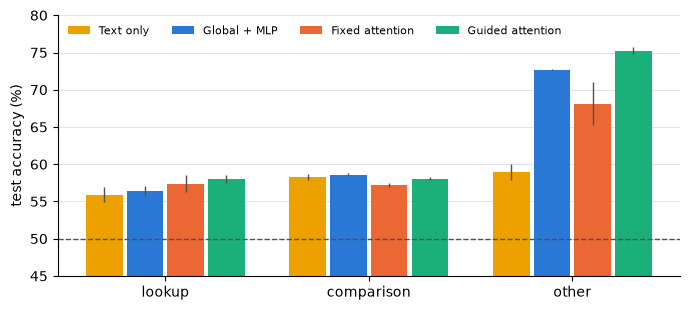

In [6]:
categories = ["lookup", "comparison", "other"]
fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.2
for i, model in enumerate(MAIN):
    x = np.arange(len(categories)) + (i - 1.5) * width
    ax.bar(x, mean.loc[model, categories], width * 0.9, yerr=std.loc[model, categories],
           color=COLORS[model], label=NAMES[model], error_kw={"lw": 1, "ecolor": "#52514e"})
ax.axhline(50, color="#52514e", lw=1, ls="--")
ax.set_xticks(np.arange(len(categories)), categories)
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(45, 80)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=4, loc="upper left", fontsize=8)
plt.tight_layout()

Per source and category, guided minus fixed attention (mean over seeds):

In [7]:
def by_group(model):
    cols = [f"{model}_seed{s}" for s in range(3)]
    correct = pd.DataFrame({c: test[c] == test.label for c in cols})
    return correct.mean(axis=1).groupby([test.source, test.category]).mean().mul(100)

pd.DataFrame({
    "guided − fixed": by_group("attention_guided") - by_group("attention_fixed"),
    "guided − global": by_group("attention_guided") - by_group("global_mlp"),
}).unstack(0).round(1)

guided − fixed               guided − global              
source            chartqa dvqa figureqa         chartqa dvqa figureqa
category                                                             
comparison           -3.8  1.8      0.9            -7.1  0.2     -0.2
lookup               -0.3  5.2      NaN             1.9  0.3      NaN
other                -7.3  8.6     -0.8             6.2  3.4     -3.8

Same bootstrap per source and per category:

In [8]:
def by_group_bootstrap(a, b):
    groups = [*test.groupby("source"), *test.groupby("category")]
    return pd.DataFrame({g: paired_bootstrap(rows, a, b) for g, rows in groups}).T

pd.concat({"guided − fixed": by_group_bootstrap("attention_guided", "attention_fixed"),
           "guided − global": by_group_bootstrap("attention_guided", "global_mlp")}, axis=1).round(3)

guided − fixed                      guided − global                \
                     diff    low   high      p            diff    low   high   
chartqa            -0.752 -2.931  1.462  0.489           0.910 -1.322  3.159   
dvqa                4.708  3.715  5.723  0.000           1.352  0.374  2.302   
figureqa            0.860 -0.382  2.131  0.180          -0.401 -1.470  0.639   
comparison          0.859 -0.130  1.866  0.095          -0.580 -1.489  0.341   
lookup              0.598 -1.435  2.661  0.577           1.664 -0.314  3.649   
other               7.131  5.351  8.873  0.000           2.584  0.948  4.195   

                   
                p  
chartqa     0.428  
dvqa        0.007  
figureqa    0.438  
comparison  0.214  
lookup      0.101  
other       0.001

Only DVQA and `other` are significant in both comparisons. The comparison-statement gain over fixed attention (+0.9) is not (p ≈ 0.1), which confirms that RQ3's hypothesis is not supported. On ChartQA and FigureQA no difference is significant.

## Shuffled-image control

Each test chart is replaced by the features of a different test chart (`src.run.shuffle_images`). A model that uses the chart should drop towards the text-only score; `text_only` ignores the image, so its score does not change.

In [9]:
runs.groupby("model", sort=False)[["all", "shuffled"]].agg(["mean", "std"]).round(1).rename(index=NAMES)

all      shuffled     
                  mean  std     mean  std
model                                    
Text only         57.6  0.6     57.6  0.6
Global + MLP      59.8  0.2     54.8  0.2
Fixed attention   58.7  0.3     52.6  0.4
Guided attention  60.3  0.1     53.5  0.6
Mean of patches   57.1  1.7     55.1  1.9

## Text shortcuts

`text_only` reaches 57.6%, so part of every model's score may come from the statements alone. We split the test pairs by how many `text_only` seeds get them right: **wrong** (0 of 3, the text shortcut points to the wrong statement), **mixed** (1 or 2 of 3, no consistent text signal) and **right** (3 of 3). On the *wrong* subset a model has to overrule the text to score; on *mixed* the text gives little help either way.

The subsets are chosen with another model's predictions, so they measure how much each model behaves like `text_only`, not image use on its own (the shuffled-image control above covers that).

In [10]:
text_votes = pd.Series(correct(test, "text_only"), index=test.index)
subset = pd.cut(text_votes, [-0.1, 0.1, 0.9, 1.1], labels=["wrong", "mixed", "right"])
shortcut = pd.DataFrame({NAMES[m]: pd.Series(correct(test, m), index=test.index).groupby(subset, observed=True).mean() * 100
                         for m in ["text_only", *MAIN[1:], "mean_patches"]})
text_choice = (text_votes.pipe(lambda v: test.label.where(v > 0.5, 1 - test.label)))
shortcut.loc["agrees with text_only"] = [np.mean([(test[f"{m}_seed{s}"] == text_choice).mean() for s in range(3)]) * 100
                                         for m in ["text_only", *MAIN[1:], "mean_patches"]]
shortcut["pairs"] = subset.value_counts()
shortcut.round(1)

,Text only,Global + MLP,Fixed attention,Guided attention,Mean of patches,pairs
wrong,0.0,20.4,34.9,35.9,34.3,3694.0
mixed,50.5,58.2,56.0,60.1,53.1,3773.0
right,100.0,86.5,76.1,76.5,74.8,5656.0
agrees with text_only,90.4,75.7,66.3,66.2,64.7,NaN


In [11]:
pd.concat({name: pd.DataFrame({k: paired_bootstrap(test[subset == name], *COMPARISONS[k])
                                 for k in ["image vs text only (global − text)", "RQ1: fixed attention − global",
                                           "RQ2: guided − fixed attention", "guided − global"]}).T
           for name in ["wrong", "mixed", "right"]}).round(3)

diff     low    high      p
wrong image vs text only (global − text)  20.411  19.212  21.617  0.000
      RQ1: fixed attention − global       14.528  12.690  16.436  0.000
      RQ2: guided − fixed attention        0.938  -0.952   2.779  0.328
      guided − global                     15.467  13.913  17.026  0.000
mixed image vs text only (global − text)   7.713   6.115   9.334  0.000
      RQ1: fixed attention − global       -2.182  -3.931  -0.457  0.014
      RQ2: guided − fixed attention        4.082   2.545   5.550  0.000
      guided − global                      1.899   0.398   3.378  0.014
right image vs text only (global − text) -13.520 -14.457 -12.597  0.000
      RQ1: fixed attention − global      -10.390 -11.697  -9.057  0.000
      RQ2: guided − fixed attention        0.413  -0.838   1.661  0.530
      guided − global                     -9.978 -11.026  -8.933  0.000

`global_mlp` behaves much more like `text_only`: it agrees with its choice on about 76% of the pairs, against 66% for the attention models. That helps it where the text is right (86.5% against 76.5% for guided attention) and hurts it where the text is wrong (20.4% against 35.9%). The attention heads lean more on the chart, but the two effects almost cancel, which is why their overall scores are so close.

On the *mixed* subset, where the text gives no consistent signal, guided attention is significantly better than both `global_mlp` (+1.9, p ≈ 0.01) and fixed attention (+4.1). So guided attention's advantage over the global embedding is clearer once text shortcuts are taken out. On the *wrong* subset every model stays below 50%: when the statement wording points to the wrong answer, the image rarely overrules it.

## Cost

Trainable parameters, training time (20 epochs, one RTX 3080) and peak extra GPU memory during training (on top of the features, which are kept on the GPU for all models).

In [12]:
runs.groupby("model", sort=False)[["params", "seconds", "memory_mb"]].mean().round(0).astype(int).rename(index=NAMES)

,params,seconds,memory_mb
model,,,
Text only,131585,6,891
Global + MLP,1575937,7,919
Fixed attention,1575937,89,2017
Guided attention,1575425,96,2018
Mean of patches,919041,9,907


## Attention maps

Attention weights over the 14×14 patch grid (averaged over the 8 heads), seed 0. For guided attention the map depends on the statement, so we show it for both candidates. These maps are qualitative only and are not evidence of causal grounding.

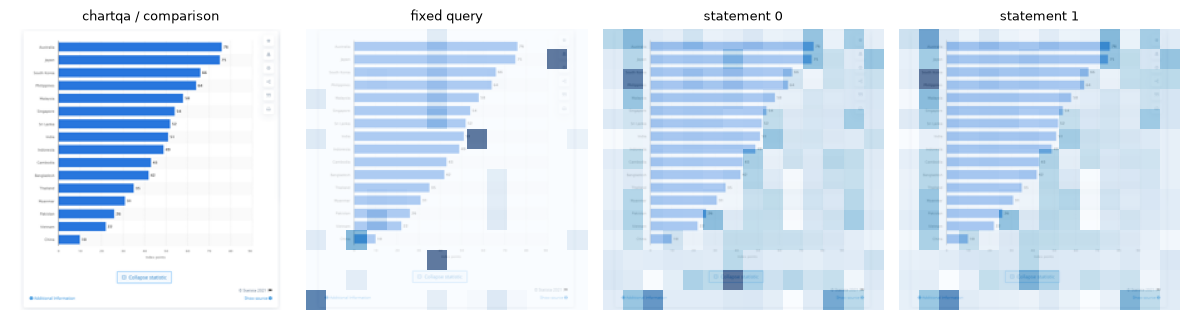

statement 0 (wrong): Japan was ranked as having the highest degree of internet freedom in 2020.
statement 1 (correct): Australia was ranked as having the highest degree of internet freedom in 2020.
guided predicts 0 | fixed predicts 0


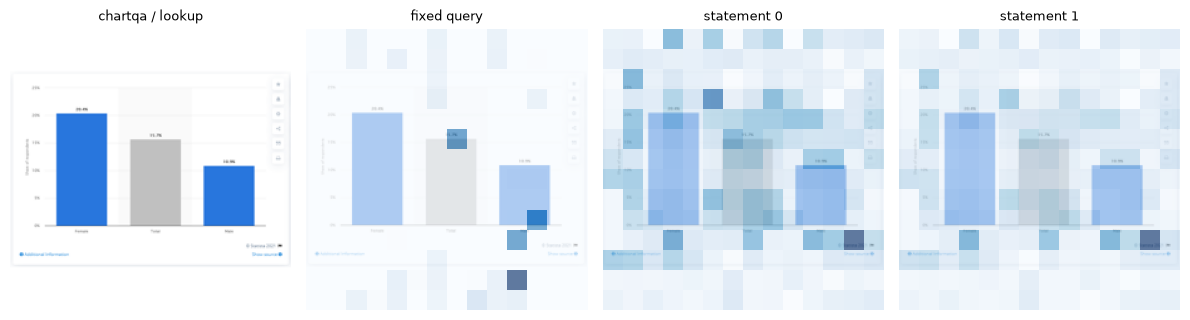

statement 0 (correct): 15.7% of high school students experienced cyber bullying between August 2018 and June 2019.
statement 1 (wrong): Eighteen percent of high school students experienced cyber bullying between August 2018 and June 2019.
guided predicts 0 | fixed predicts 0


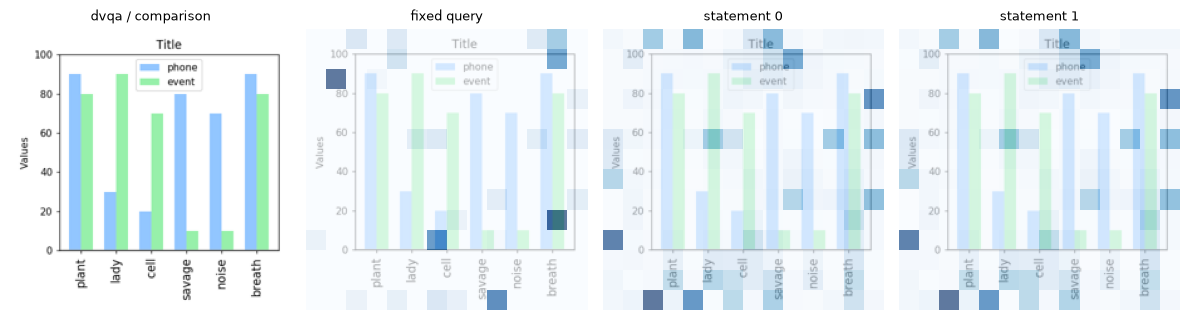

statement 0 (correct): There are three groups of bars that contain at least one bar with a value greater than 80.
statement 1 (wrong): There are two groups of bars that contain at least one bar with a value greater than 80.
guided predicts 0 | fixed predicts 1


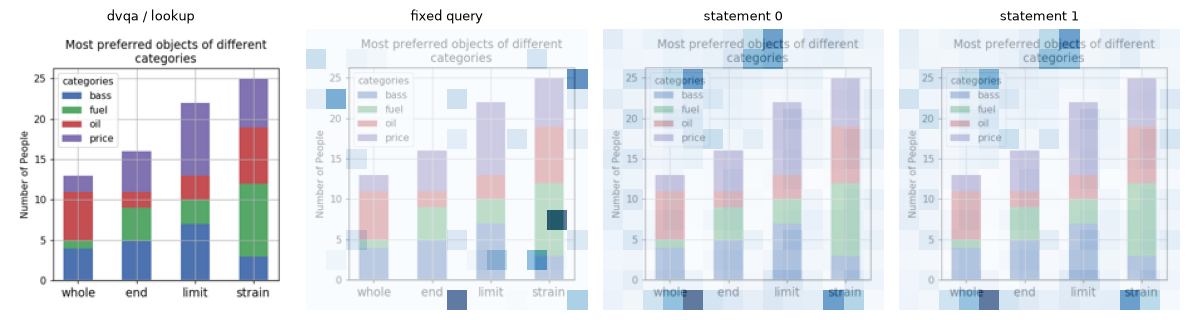

statement 0 (wrong): There are 12 total people who preferred the object across all the categories.
statement 1 (correct): There are 16 total people who preferred the object across all the categories.
guided predicts 1 | fixed predicts 1


In [13]:
features = Features()
models = {}
for name in ["attention_fixed", "attention_guided"]:
    models[name] = MODELS[name]().to(features.device).eval()
    models[name].load_state_dict(torch.load(CHECKPOINT_DIR / f"{name}_seed0.pt"))

@torch.no_grad()
def attention_maps(i):
    rows = features.split("test")[i:i + 1]
    _, patches, t0, t1 = features.inputs(rows)
    fixed = models["attention_fixed"]
    query = torch.nn.functional.normalize(fixed.query, dim=-1)
    _, w_fixed = fixed.attention(query, patches, patches)
    _, w_guided = models["attention_guided"].attention(torch.stack([t0, t1], 1), patches, patches)
    return w_fixed[0, 0].view(14, 14).cpu(), w_guided[0].view(2, 14, 14).cpu()

def show(i):
    row = test.iloc[i]
    image = pad_square(Image.open(RAW_DIR / row.image).convert("RGB")).resize((224, 224))
    fixed, guided = attention_maps(i)
    maps = {"fixed query": fixed, "statement 0": guided[0], "statement 1": guided[1]}
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
    axes[0].imshow(image)
    axes[0].set_title(f"{row.source} / {row.category}", fontsize=9)
    for ax, (title, w) in zip(axes[1:], maps.items()):
        ax.imshow(image)
        ax.imshow(w, cmap="Blues", alpha=0.65, extent=(0, 224, 224, 0), interpolation="nearest")
        ax.set_title(title, fontsize=9)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    for k in (0, 1):
        mark = "correct" if row.label == k else "wrong"
        print(f"statement {k} ({mark}): {row[f'option_{k}']}")
    print("guided predicts", row.attention_guided_seed0, "| fixed predicts", row.attention_fixed_seed0)

examples = (test.reset_index().groupby(["source", "category"]).sample(1, random_state=0)
            .query("category != 'other' or source == 'dvqa'")["index"].tolist())
for i in examples[:4]:
    show(i)

Attention entropy (in nats; uniform over 196 patches = 5.28) on the test set, to see how spread out the attention is:

In [14]:
@torch.no_grad()
def entropy(name):
    model, out = models[name], []
    for rows in features.split("test").split(1024):
        _, patches, t0, t1 = features.inputs(rows)
        if name == "attention_fixed":
            query = torch.nn.functional.normalize(model.query, dim=-1).expand(len(rows), -1, -1)
        else:
            query = torch.stack([t0, t1], 1)
        _, w = model.attention(query, patches, patches)
        out.append(-(w * w.clamp_min(1e-12).log()).sum(-1).mean(1))
    return torch.cat(out).cpu().numpy()

pd.DataFrame({NAMES[n]: pd.Series(entropy(n)).groupby(test.source).mean() for n in models}).round(2)

,Fixed attention,Guided attention
source,,
chartqa,2.79,5.10
dvqa,2.83,5.03
figureqa,2.94,5.02


Does the map actually depend on the statement? For guided attention we measure the total variation distance between the maps of the two candidates (0 = identical, 1 = disjoint), and the test accuracy when both candidates share one query, the normalized mean of the two statements. With a shared query the aggregated image vector is the same for both candidates, as in the fixed and global models, so the comparison isolates statement-specific aggregation.

In [15]:
@torch.no_grad()
def guidance_check(seed):
    model = MODELS["attention_guided"]().to(features.device).eval()
    model.load_state_dict(torch.load(CHECKPOINT_DIR / f"attention_guided_seed{seed}.pt"))
    rows_all = features.split("test")
    tv, shared = [], []
    for rows in rows_all.split(1024):
        _, patches, t0, t1 = features.inputs(rows)
        t = torch.stack([t0, t1], 1)
        _, w = model.attention(t, patches, patches)
        tv.append(0.5 * (w[:, 0] - w[:, 1]).abs().sum(-1))
        q = torch.nn.functional.normalize(t0 + t1, dim=-1)[:, None]
        z, _ = model.attention(q, patches, patches)
        z = torch.nn.functional.normalize(z, dim=-1).expand_as(t)
        shared.append(model.mlp(torch.cat([z, t], 2)).squeeze(2).argmax(1))
    shared = (torch.cat(shared) == rows_all[:, 3]).float().mean().item() * 100
    return {"seed": seed, "TV distance": torch.cat(tv).mean().item(), "accuracy": wide.loc[("attention_guided", seed), "all"],
            "accuracy, shared query": shared}

pd.DataFrame([guidance_check(s) for s in range(3)]).set_index("seed").round(3)

,TV distance,accuracy,"accuracy, shared query"
seed,,,
0,0.048,60.4,53.799
1,0.031,60.4,54.629
2,0.049,60.2,51.886


## Representative errors

Statements that guided attention gets wrong with all three seeds, by category.

In [16]:
guided_cols = [f"attention_guided_seed{s}" for s in range(3)]
fixed_cols = [f"attention_fixed_seed{s}" for s in range(3)]
guided_wrong = (test[guided_cols].ne(test.label, axis=0)).all(axis=1)
fixed_wrong = (test[fixed_cols].ne(test.label, axis=0)).all(axis=1)
print(f"always wrong: guided {guided_wrong.mean():.1%}, fixed {fixed_wrong.mean():.1%}")

pd.set_option("display.max_colwidth", 90)
errors = test[guided_wrong].groupby("category").sample(3, random_state=0)
errors.assign(correct=errors.apply(lambda r: r[f"option_{r.label}"], axis=1),
              chosen=errors.apply(lambda r: r[f"option_{1 - r.label}"], axis=1))[["source", "category", "correct", "chosen"]]

always wrong: guided 15.8%, fixed 25.6%


,source,category,correct,chosen
954,chartqa,comparison,The second largest red bar has a value of 251.2.,The second largest red bar has a value of 197.2.
5574,figureqa,comparison,Orchid is not greater than Dark Red.,Orchid is greater than Dark Red.
6230,figureqa,comparison,Medium Seafoam is the roughest.,Medium Seafoam is not the roughest.
215,chartqa,lookup,The average monthly price for crude palm oil in Malaysia in December 2020 was 3620.5.,The average monthly price for crude palm oil in Malaysia in December 2020 was 3261.1.
1762,chartqa,lookup,The average cost per day to stay in a hospital in Spain was 424.,The average cost per day to stay in a hospital in Spain was 342.
3506,chartqa,lookup,Cloudflare Security's market share was 81.38 in April 2021.,Cloudflare Security's market share was 97.85 in April 2021.
4715,figureqa,other,Slate does not intersect Dark Seafoam.,Slate intersects Dark Seafoam.
9825,dvqa,other,The steelblue color represents the bass dataset.,The steelblue color represents the mass dataset.
11223,dvqa,other,The label of the second bar from the left in each group is motion.,The label of the second bar from the left in each group is emotion.


Two of these charts with attention:

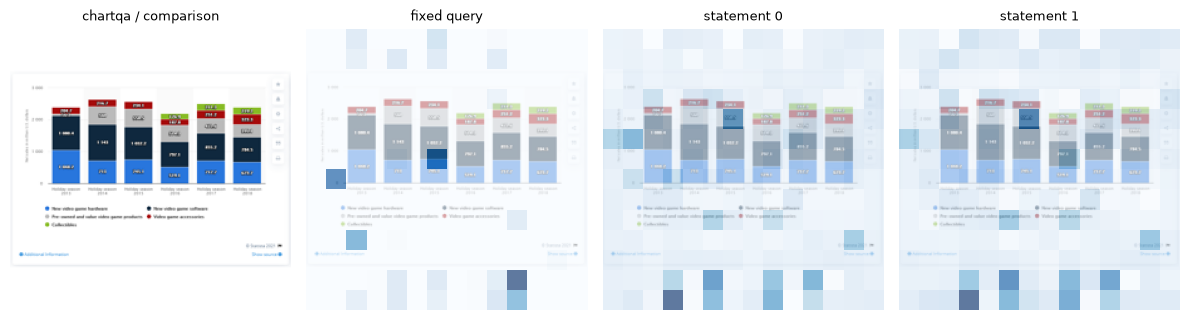

statement 0 (wrong): The second largest red bar has a value of 197.2.
statement 1 (correct): The second largest red bar has a value of 251.2.
guided predicts 0 | fixed predicts 1


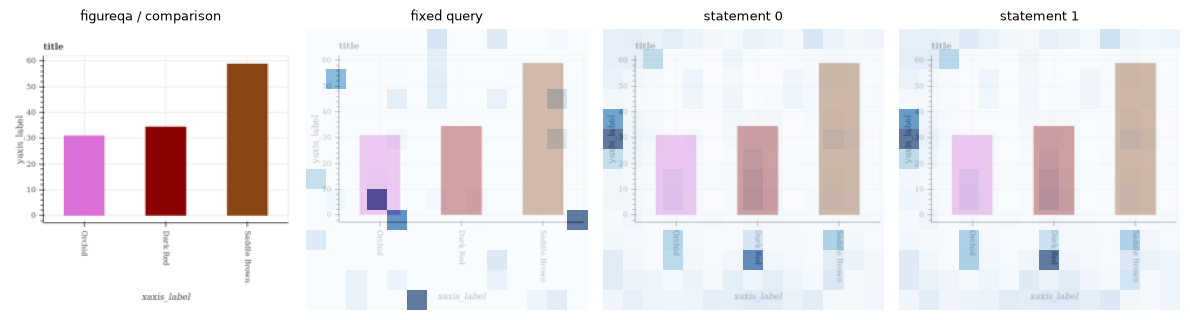

statement 0 (correct): Orchid is not greater than Dark Red.
statement 1 (wrong): Orchid is greater than Dark Red.
guided predicts 1 | fixed predicts 1


In [17]:
for i in errors.index[:2]:
    show(i)

Statements where guided attention is right with all seeds and fixed attention is wrong with all seeds:

407 statements; {'comparison': 215, 'lookup': 137, 'other': 55}


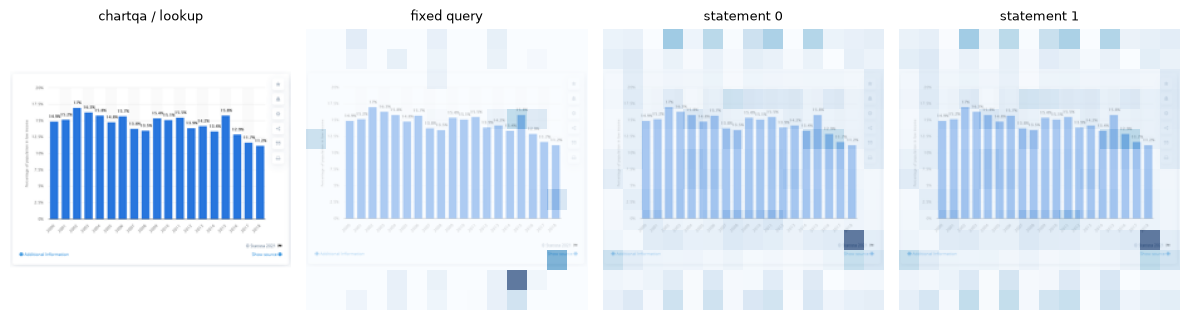

statement 0 (wrong): 13.5% of the population of British Columbia was considered to be in low income in 2018.
statement 1 (correct): 11.2% of the population of British Columbia was considered to be in low income in 2018.
guided predicts 1 | fixed predicts 0


In [18]:
wins = test[~guided_wrong & test[guided_cols].eq(test.label, axis=0).all(axis=1) & fixed_wrong]
print(len(wins), "statements;", wins.category.value_counts().to_dict())
show(wins.index[0])

## Summary

- **Image vs text only.** `text_only` reaches 57.6%, so the statements contain shortcuts. The image adds 2.2 points (`global_mlp`), mostly on DVQA. With shuffled charts, all image models fall below `text_only`, so they do use the matching chart.
- **RQ1 (regional aggregation).** Not supported: fixed attention is 1.0 ± 0.5 points below the global embedding.
- **RQ2 (text conditioning).** Supported: guided attention is 1.6 ± 0.4 points above fixed attention (95% CI over charts 0.7 to 2.5, p = 0.001). It has the highest and most stable score (60.3 ± 0.1), but its +0.6 over `global_mlp` is not significant (CI −0.3 to 1.5, p = 0.18). Its attention is almost uniform, and the maps of the two statements barely differ (TV 0.03–0.05). Still, removing the per-statement query (shared query) or the learned weights (`mean_patches`) costs 3–7 points. The benefit comes from small statement-dependent changes in the aggregated vector, not from visibly localized attention.
- **RQ3 (statement type).** The hypothesis is not supported. The gain over fixed attention is small for comparisons (+0.9) and lookups (+0.6). It is large for `other` (+7.1), mostly DVQA statements about legends, colors and labels.
- **Text shortcuts.** `global_mlp` follows `text_only` much more (76% agreement against 66% for the attention models): it wins where the text shortcut is right and loses where it is wrong, and the two effects nearly cancel. On pairs where the text gives no consistent signal, guided attention beats `global_mlp` significantly (+1.9, p ≈ 0.01) and fixed attention by 4.1 points.
- **Cost.** At the same parameter count, attention needs about 13× the training time and 2× the peak GPU memory.
- **Limitation.** At 224×224, small text and exact values are hard to read. ChartQA and FigureQA stay near chance for every model, which points to an encoding bottleneck that better aggregation cannot fix.